In [7]:
!pip install numpy opencv-python matplotlib seaborn torch torchvision pillow tqdm scikit-learn

import os

import random
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optimS
from torch.utils.data import DataLoader, Dataset, ConcatDataset

from torchvision import transforms, datasets
import torchvision.transforms.functional as TF
from PIL import Image
from tqdm import tqdm

from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report


[notice] A new release of pip is available: 25.0.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
%matplotlib inline

import os
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, ConcatDataset

from torchvision import transforms, datasets
import torchvision.transforms.functional as TF
from PIL import Image
from tqdm import tqdm

from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report

IN_COLAB = 'google.colab' in str(get_ipython()) if hasattr(__builtins__, '__IPYTHON__') else False

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Google Drive mounted!")
else:
    print("Running locally")

Running locally


In [9]:
if IN_COLAB:
    DATA_DIR = '/content/drive/MyDrive/garbage_classification'
else:
    DATA_DIR = 'garbage_classification'

print(f"Dataset path: {DATA_DIR}")

RANDOM_SEED = 42
BATCH_SIZE = 64
IMAGE_SIZE = 227
NUM_WORKERS = 0
PIN_MEMORY = True

ENHANCER_EPOCHS = 5
ENHANCER_LR = 0.001
ENHANCER_LR = 0.0003

CLASSIFIER_EPOCHS = 15
CLASSIFIER_LR = 0.001
CLASSIFIER_LR = 0.0003

BRIGHTNESS_FACTOR = 0.2
NOISE_RATIO = 0.01

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Dataset path: garbage_classification
Using device: cuda


In [10]:
os.listdir(DATA_DIR)

['glass', 'metal', 'paper', 'plastic']

In [11]:
classes = os.listdir(DATA_DIR)
num_classes = len(classes)

print(f"Dataset Directory: {DATA_DIR}")
print(f"Number of Classes: {num_classes}")
print(f"Classes: {classes}")

Dataset Directory: garbage_classification
Number of Classes: 4
Classes: ['glass', 'metal', 'paper', 'plastic']


In [12]:
def apply_low_light(image_np, brightness_factor=0.2, noise_ratio=0.01):
    hsv = cv2.cvtColor(image_np, cv2.COLOR_RGB2HSV)
    hsv = hsv.astype(np.float32)

    hsv[..., 2] = hsv[..., 2] * brightness_factor
    hsv = np.clip(hsv, 0, 255).astype(np.uint8)

    darkened = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

    mask = np.random.rand(*darkened.shape[:2])
    darkened[mask < noise_ratio] = 0
    darkened[mask > (1 - noise_ratio)] = 255

    return darkened

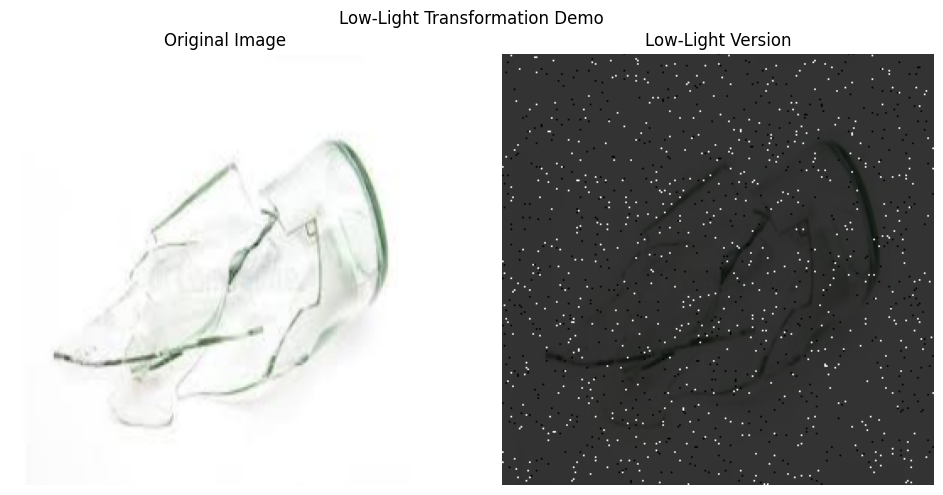

In [13]:
sample_class = classes[0]
sample_path = os.path.join(DATA_DIR, sample_class)
sample_file = os.listdir(sample_path)[0]
sample_img = cv2.imread(os.path.join(sample_path, sample_file))
sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
sample_img = cv2.resize(sample_img, (256, 256))

low_light_img = apply_low_light(sample_img, BRIGHTNESS_FACTOR, NOISE_RATIO)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(sample_img)
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(low_light_img)
axes[1].set_title('Low-Light Version')
axes[1].axis('off')

plt.suptitle('Low-Light Transformation Demo')
plt.tight_layout()
plt.show()

In [14]:
class EnhancementCNN(nn.Module):
    def __init__(self):
        super(EnhancementCNN, self).__init__()

        self.path1_conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.path1_conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.path1_conv3 = nn.Conv2d(32, 64, kernel_size=2, padding='same')

        self.path2_conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.path2_conv2 = nn.Conv2d(32, 64, kernel_size=2, padding='same')
        self.path2_conv3 = nn.Conv2d(64, 64, kernel_size=2, padding='same')

        self.path3_conv1 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.path3_conv2 = nn.Conv2d(64, 32, kernel_size=3, padding=1)
        self.path3_conv3 = nn.Conv2d(32, 16, kernel_size=2, padding='same')

        self.path3a_conv1 = nn.Conv2d(64, 32, kernel_size=3, padding=1)
        self.path3a_conv2 = nn.Conv2d(32, 16, kernel_size=2, padding='same')

        self.path3b_conv1 = nn.Conv2d(64, 16, kernel_size=2, padding='same')

        self.path4_conv1 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
        self.path4_conv2 = nn.Conv2d(64, 16, kernel_size=3, padding=1)

        self.out_conv1 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
        self.out_conv2 = nn.Conv2d(16, 16, kernel_size=2, padding='same')
        self.out_final = nn.Conv2d(16, 3, kernel_size=3, padding=1)

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        p1 = self.relu(self.path1_conv1(x))
        p1 = self.relu(self.path1_conv2(p1))
        p1 = self.relu(self.path1_conv3(p1))

        p2 = self.relu(self.path2_conv1(x))
        p2 = self.relu(self.path2_conv2(p2))
        p2_branch = self.relu(self.path2_conv3(p2))

        merge1 = p1 + p2 + p2_branch

        p3 = self.relu(self.path3_conv1(merge1))
        p3 = self.relu(self.path3_conv2(p3))
        p3 = self.relu(self.path3_conv3(p3))

        p3a = self.relu(self.path3a_conv1(merge1))
        p3a = self.relu(self.path3a_conv2(p3a))

        p3b = self.relu(self.path3b_conv1(merge1))

        merge2 = p3 + p3a + p3b

        p4 = self.relu(self.path4_conv1(merge2))
        p4_skip = self.relu(self.path4_conv2(merge1))

        merge3 = p4 + p4_skip + merge2

        out = self.relu(self.out_conv1(merge3))
        out = self.relu(self.out_conv2(out))
        out = self.relu(self.out_final(out))

        return out

In [15]:
from torchvision import models

class ClassificationCNN(nn.Module):
    def __init__(self, num_classes):
        super(ClassificationCNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 96, kernel_size=11, stride=4, padding=0)
        self.bn1 = nn.BatchNorm2d(96)
        self.pool1 = nn.MaxPool2d(kernel_size=3, stride=2)

        self.conv2 = nn.Conv2d(96, 256, kernel_size=5, stride=1, padding='same')
        self.bn2 = nn.BatchNorm2d(256)
        self.pool2 = nn.MaxPool2d(kernel_size=3, stride=2)

        self.conv3 = nn.Conv2d(256, 256, kernel_size=3, stride=1, padding='same')
        self.pool3 = nn.MaxPool2d(kernel_size=3, stride=2)

        self.fc1 = nn.Linear(9216, 9216)
        self.fc2 = nn.Linear(9216, 4096)
        self.fc3 = nn.Linear(4096, 4096)
        self.classifier = nn.Linear(4096, num_classes)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool1(x)
        x = self.bn1(x)

        x = F.relu(self.conv2(x))
        x = self.pool2(x)
        x = self.bn2(x)

        x = F.relu(self.conv3(x))
        x = self.pool3(x)

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))

        x = self.classifier(x)
        return x

class RecyclingVGG(nn.Module):
    def __init__(self, num_classes=4, pre_trained=True):
        super(RecyclingVGG, self).__init__()

        weights = models.VGG16_Weights.DEFAULT if pre_trained else None
        self.model = models.vgg16(weights=weights)

        for param in self.model.features.parameters():
            param.requires_grad = False

        num_features = self.model.classifier[6].in_features
        self.model.classifier[6] = nn.Linear(num_features, num_classes)

    def forward(self, x):
        return self.model(x)
class RecyclingResNet50(nn.Module):
    def __init__(self, num_classes=4, pre_trained=True):
        super(RecyclingResNet50, self).__init__()

        weights = models.ResNet50_Weights.DEFAULT if pre_trained else None
        self.model = models.resnet50(weights=weights)

        for param in self.model.parameters():
            param.requires_grad = False

        num_features = self.model.fc.in_features
        self.model.fc = nn.Linear(num_features, num_classes)

    def forward(self, x):
        return self.model(x)

In [16]:
class EnhancerDataset(Dataset):
    def __init__(self, root_dir, brightness_factor=0.2, noise_ratio=0.01):
        self.data = datasets.ImageFolder(root=root_dir)
        self.brightness_factor = brightness_factor
        self.noise_ratio = noise_ratio

        self.resize = transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.CenterCrop(IMAGE_SIZE),
        ])
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img, _ = self.data[idx]
        img = self.resize(img)

        img_np = np.array(img)
        low_light_np = apply_low_light(img_np, self.brightness_factor, self.noise_ratio)

        original_tensor = self.to_tensor(img)
        low_light_tensor = self.to_tensor(low_light_np)

        return low_light_tensor, original_tensor

In [17]:
class ClassifierDataset(Dataset):
    def __init__(self, root_dir, apply_augmentation=False,
                 brightness_factor=0.2, noise_ratio=0.01):
        self.data = datasets.ImageFolder(root=root_dir)
        self.apply_augmentation = apply_augmentation
        self.brightness_factor = brightness_factor
        self.noise_ratio = noise_ratio

        self.resize = transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.CenterCrop(IMAGE_SIZE),
        ])

        self.augment = transforms.Compose([
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomVerticalFlip(p=0.3),
            transforms.RandomRotation(degrees=15),
            transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
        ])

        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img, label = self.data[idx]
        img = self.resize(img)

        img_np = np.array(img)
        low_light_np = apply_low_light(img_np, self.brightness_factor, self.noise_ratio)

        low_light_pil = Image.fromarray(low_light_np)

        if self.apply_augmentation:
            low_light_pil = self.augment(low_light_pil)

        return self.to_tensor(low_light_pil), label

In [18]:
import os

print("Current working directory:", os.getcwd())
print("DATA_DIR:", DATA_DIR)
print("İçindekiler:", os.listdir(DATA_DIR))

Current working directory: c:\kod\AIN_proje
DATA_DIR: garbage_classification
İçindekiler: ['glass', 'metal', 'paper', 'plastic']


In [19]:
!rm -rf /workspace/garbage_classification/.ipynb_checkpoints

'rm' is not recognized as an internal or external command,
operable program or batch file.


In [20]:
print("="*50)
print("Preparing Enhancement Model Dataset")
print("="*50)
from sklearn.model_selection import train_test_split

enhancer_dataset = EnhancerDataset(
    root_dir=DATA_DIR,
    brightness_factor=BRIGHTNESS_FACTOR,
    noise_ratio=NOISE_RATIO
)

labels = [enhancer_dataset.data[i][1] for i in range(len(enhancer_dataset))]

indices = list(range(len(enhancer_dataset)))
train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    stratify=labels,
    random_state=RANDOM_SEED
)

train_enh_ds = torch.utils.data.Subset(enhancer_dataset, train_indices)
val_enh_ds = torch.utils.data.Subset(enhancer_dataset, val_indices)

train_enh_loader = DataLoader(train_enh_ds, batch_size=BATCH_SIZE, shuffle=True,
                               num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_enh_loader = DataLoader(val_enh_ds, batch_size=BATCH_SIZE, shuffle=False,
                             num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

print(f"Total images: {len(enhancer_dataset)}")
print(f"Training samples: {len(train_enh_ds)}")
print(f"Validation samples: {len(val_enh_ds)}")

Preparing Enhancement Model Dataset
Total images: 4695
Training samples: 3756
Validation samples: 939


In [21]:
def check_distribution(indices, all_labels, name):
    label_counts = {}

    for idx in indices:
        label = all_labels[idx]
        label_counts[label] = label_counts.get(label, 0) + 1

    print(f"\n{name}:")
    total = sum(label_counts.values())
    for label, count in sorted(label_counts.items()):
        print(f"  Class {label}: {count} ({100*count/total:.1f}%)")

check_distribution(train_indices, labels, "Train Set")
check_distribution(val_indices, labels, "Validation Set")


Train Set:
  Class 0: 1609 (42.8%)
  Class 1: 615 (16.4%)
  Class 2: 840 (22.4%)
  Class 3: 692 (18.4%)

Validation Set:
  Class 0: 402 (42.8%)
  Class 1: 154 (16.4%)
  Class 2: 210 (22.4%)
  Class 3: 173 (18.4%)


In [ ]:
print("="*50)
print("Preparing Classification Model Dataset")
print("="*50)

ds_pure_lowlight = ClassifierDataset(
    root_dir=DATA_DIR,
    apply_augmentation=False,
    brightness_factor=BRIGHTNESS_FACTOR,
    noise_ratio=NOISE_RATIO
)

ds_augmented_lowlight = ClassifierDataset(
    root_dir=DATA_DIR,
    apply_augmentation=True,
    brightness_factor=BRIGHTNESS_FACTOR,
    noise_ratio=NOISE_RATIO
)

combined_dataset = ConcatDataset([ds_pure_lowlight, ds_augmented_lowlight])

labels = []
for i in range(len(ds_pure_lowlight)):
    labels.append(ds_pure_lowlight.data[i][1])
for i in range(len(ds_augmented_lowlight)):
    labels.append(ds_augmented_lowlight.data[i][1])

indices = list(range(len(combined_dataset)))
train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    stratify=labels,
    random_state=RANDOM_SEED
)

train_clf_ds = torch.utils.data.Subset(combined_dataset, train_indices)
val_clf_ds = torch.utils.data.Subset(combined_dataset, val_indices)

train_clf_loader = DataLoader(train_clf_ds, batch_size=BATCH_SIZE, shuffle=True,
                               num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_clf_loader = DataLoader(val_clf_ds, batch_size=BATCH_SIZE, shuffle=False,
                             num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

print(f"Pure low-light images: {len(ds_pure_lowlight)}")
print(f"Augmented low-light images: {len(ds_augmented_lowlight)}")
print(f"Combined total: {len(combined_dataset)}")
print(f"Training samples: {len(train_clf_ds)}")
print(f"Validation samples: {len(val_clf_ds)}")

Preparing Classification Model Dataset
Pure low-light images: 4695
Augmented low-light images: 4695
Combined total: 9390
Training samples: 7512
Validation samples: 1878


In [23]:
check_distribution(train_indices, labels, "Train Set")
check_distribution(val_indices, labels, "Validation Set")


Train Set:
  Class 0: 3218 (42.8%)
  Class 1: 1230 (16.4%)
  Class 2: 1680 (22.4%)
  Class 3: 1384 (18.4%)

Validation Set:
  Class 0: 804 (42.8%)
  Class 1: 308 (16.4%)
  Class 2: 420 (22.4%)
  Class 3: 346 (18.4%)


In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class StructureFocusedLoss(nn.Module):
    def __init__(
        self,
        charbonnier_weight=1.0,
        ssim_weight=1.0,
        edge_weight=0.5,
        laplacian_weight=0.0,
        ssim_window=11,
        eps=1e-3,
        return_log = False,
        edge_on_luma=True,
    ):
        super().__init__()
        self.charbonnier_weight = charbonnier_weight
        self.ssim_weight = ssim_weight
        self.edge_weight = edge_weight
        self.laplacian_weight = laplacian_weight
        self.ssim_window = ssim_window
        self.eps = eps
        self.return_log = return_log
        self.edge_on_luma = edge_on_luma

        kx = torch.tensor([[-1, 0, 1],
                           [-2, 0, 2],
                           [-1, 0, 1]], dtype=torch.float32).view(1, 1, 3, 3)
        ky = torch.tensor([[-1, -2, -1],
                           [ 0,  0,  0],
                           [ 1,  2,  1]], dtype=torch.float32).view(1, 1, 3, 3)
        self.register_buffer("sobel_x", kx)
        self.register_buffer("sobel_y", ky)

        lap = torch.tensor([[0,  1, 0],
                            [1, -4, 1],
                            [0,  1, 0]], dtype=torch.float32).view(1, 1, 3, 3)
        self.register_buffer("laplacian_k", lap)

    def charbonnier_loss(self, pred, target):
        diff = pred - target
        return torch.mean(torch.sqrt(diff * diff + self.eps * self.eps))

    def ssim_loss(self, pred, target, window_size=None):
        if window_size is None:
            window_size = self.ssim_window

        C1 = 0.01 ** 2
        C2 = 0.03 ** 2

        mu_x = F.avg_pool2d(pred, window_size, stride=1, padding=window_size // 2)
        mu_y = F.avg_pool2d(target, window_size, stride=1, padding=window_size // 2)

        mu_x2 = mu_x * mu_x
        mu_y2 = mu_y * mu_y
        mu_xy = mu_x * mu_y

        sigma_x2 = F.avg_pool2d(pred * pred, window_size, stride=1, padding=window_size // 2) - mu_x2
        sigma_y2 = F.avg_pool2d(target * target, window_size, stride=1, padding=window_size // 2) - mu_y2
        sigma_xy = F.avg_pool2d(pred * target, window_size, stride=1, padding=window_size // 2) - mu_xy

        ssim = ((2 * mu_xy + C1) * (2 * sigma_xy + C2)) / ((mu_x2 + mu_y2 + C1) * (sigma_x2 + sigma_y2 + C2))
        return 1.0 - ssim.mean()

    def _to_luma(self, x):
        if x.shape[1] == 3:
            r, g, b = x[:, 0:1], x[:, 1:2], x[:, 2:3]
            return 0.2989 * r + 0.5870 * g + 0.1140 * b
        return x.mean(dim=1, keepdim=True)

    def edge_loss(self, pred, target):
        if self.edge_on_luma:
            pred_g = self._to_luma(pred)
            target_g = self._to_luma(target)
        else:
            pred_g = self._to_luma(pred)
            target_g = self._to_luma(target)

        gx_p = F.conv2d(pred_g, self.sobel_x, padding=1)
        gy_p = F.conv2d(pred_g, self.sobel_y, padding=1)
        gx_t = F.conv2d(target_g, self.sobel_x, padding=1)
        gy_t = F.conv2d(target_g, self.sobel_y, padding=1)

        return F.l1_loss(gx_p, gx_t) + F.l1_loss(gy_p, gy_t)

    def laplacian_loss(self, pred, target):
        pred_g = self._to_luma(pred)
        target_g = self._to_luma(target)
        lp = F.conv2d(pred_g, self.laplacian_k, padding=1)
        lt = F.conv2d(target_g, self.laplacian_k, padding=1)
        return F.l1_loss(lp, lt)

    def forward(self, pred, target):
        charb = self.charbonnier_loss(pred, target)
        ssim = self.ssim_loss(pred, target)
        edge = self.edge_loss(pred, target)

        total = (self.charbonnier_weight * charb +
                 self.ssim_weight * ssim +
                 self.edge_weight * edge)

        lap = None
        if self.laplacian_weight and self.laplacian_weight > 0:
            lap = self.laplacian_loss(pred, target)
            total = total + self.laplacian_weight * lap

        logs = {
            "charbonnier": charb.item(),
            "ssim": ssim.item(),
            "edge": edge.item(),
        }
        if lap is not None:
            logs["laplacian"] = lap.item()
        if self.return_log:
            return total, logs
        else:
            return total

In [25]:
train_labels = [labels[i] for i in train_indices]
class_counts = torch.bincount(torch.tensor(train_labels))
class_weights = 1.0 / class_counts.float()
class_weights = class_weights / class_weights.sum()
print(class_weights)

tensor([0.1273, 0.3330, 0.2438, 0.2959])


In [26]:
class_weights = torch.tensor([0.16, 0.3, 0.18, 0.2645])
class_weights = class_weights / class_weights.sum()
print(class_weights)

tensor([0.1769, 0.3317, 0.1990, 0.2924])


In [27]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.gamma = gamma

        if alpha is not None:
            self.register_buffer("alpha", torch.tensor(alpha, dtype=torch.float32))
        else:
            self.alpha = None

    def forward(self, logits, targets):
        logp = F.log_softmax(logits, dim=1)
        logp_t = logp.gather(1, targets.unsqueeze(1)).squeeze(1)
        p_t = logp_t.exp()

        focal = (1.0 - p_t).pow(self.gamma)

        if self.alpha is not None:
            alpha_t = self.alpha.gather(0, targets)
            loss = -alpha_t * focal * logp_t
        else:
            loss = -focal * logp_t

        return loss.mean()

In [28]:
print("="*50)
print("Initializing Models")
print("="*50)

enhancer_model = EnhancementCNN().to(device)
enhancer_optimizer = optim.Adam(enhancer_model.parameters(), lr=ENHANCER_LR)

enhancer_criterion = StructureFocusedLoss().to(device)

print(f"\n[Model 1] Enhancement CNN")
print(f"  - Purpose: Restore brightness from low-light images")
print(f"  - Loss: MSE (pixel-wise reconstruction)")
print(f"  - Learning Rate: {ENHANCER_LR}")

criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

classifier_model = ClassificationCNN(num_classes=num_classes).to(device)
classifier_optimizer = optim.Adam(classifier_model.parameters(), lr=CLASSIFIER_LR)
classifier_criterion = FocalLoss(gamma = 2.0).to(device)
print(f"\n[Model 2] Classification CNN")
print(f"  - Purpose: Classify garbage into {num_classes} categories")
print(f"  - Loss: CrossEntropy")
print(f"  - Learning Rate: {CLASSIFIER_LR}")

NORM_MEAN = torch.tensor([0.485, 0.456, 0.406]).to(device).view(1, 3, 1, 1)
NORM_STD = torch.tensor([0.229, 0.224, 0.225]).to(device).view(1, 3, 1, 1)

Initializing Models

[Model 1] Enhancement CNN
  - Purpose: Restore brightness from low-light images
  - Loss: MSE (pixel-wise reconstruction)
  - Learning Rate: 0.0003

[Model 2] Classification CNN
  - Purpose: Classify garbage into 4 categories
  - Loss: CrossEntropy
  - Learning Rate: 0.0003


In [29]:
print(class_weights)

tensor([0.1769, 0.3317, 0.1990, 0.2924])


In [30]:
scaler = torch.amp.GradScaler('cuda') if device.type == 'cuda' else None

def train_enhancer_epoch(model, loader, optimizer, criterion, epoch):
    model.train()
    total_loss = 0.0

    loop = tqdm(loader, desc=f"Enhancer Epoch {epoch}", leave=True)
    for low_light, original in loop:
        low_light = low_light.to(device, non_blocking=True)
        original = original.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        if scaler is not None:
            with torch.amp.autocast('cuda'):
                enhanced = model(low_light).clamp(0, 1)
                loss = criterion(enhanced, original)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            enhanced = model(low_light).clamp(0, 1)
            loss = criterion(enhanced, original)

            loss.backward()
            optimizer.step()

        total_loss += loss.item()
        loop.set_postfix(loss=f"{loss.item():.4f}")

    return total_loss / len(loader)

def validate_enhancer(model, loader, criterion):
    model.eval()
    total_loss = 0.0

    with torch.no_grad():
        for low_light, original in tqdm(loader, desc="Validating", leave=False):
            low_light = low_light.to(device, non_blocking=True)
            original = original.to(device, non_blocking=True)

            with torch.amp.autocast('cuda', enabled=(scaler is not None)):
                enhanced = model(low_light).clamp(0, 1)
                loss = criterion(enhanced, original)

            total_loss += loss.item()

    return total_loss / len(loader)

In [31]:
def train_classifier_epoch(enhancer, classifier, loader, optimizer, criterion, epoch):
    enhancer.eval()
    classifier.train()

    total_loss = 0.0
    correct = 0
    total = 0

    loop = tqdm(loader, desc=f"Classifier Epoch {epoch}", leave=True)
    for images, labels in loop:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        if scaler is not None:
            with torch.amp.autocast('cuda'):
                with torch.no_grad():
                    enhanced = enhancer(images)

                normalized = (enhanced - NORM_MEAN) / NORM_STD

                outputs = classifier(normalized)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            with torch.no_grad():
                enhanced = enhancer(images)
            normalized = (enhanced - NORM_MEAN) / NORM_STD
            outputs = classifier(normalized)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        total_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        loop.set_postfix(loss=f"{loss.item():.4f}", acc=f"{100*correct/total:.1f}%")

    accuracy = 100 * correct / total
    avg_loss = total_loss / len(loader)

    return avg_loss, accuracy

def validate_classifier(enhancer, classifier, loader, criterion):
    enhancer.eval()
    classifier.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Validating", leave=False):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast('cuda', enabled=(scaler is not None)):
                enhanced = enhancer(images)
                normalized = (enhanced - NORM_MEAN) / NORM_STD
                outputs = classifier(normalized)
                loss = criterion(outputs, labels)

            total_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    avg_loss = total_loss / len(loader)

    return avg_loss, accuracy

In [ ]:
"""print("="*60)
print("STAGE 1: Training Enhancement Model")
print("="*60)
print(f"Epochs: {ENHANCER_EPOCHS}")
print(f"Training samples: {len(train_enh_ds)}")
print("-"*60)

best_enh_loss = float('inf')
enhancer_history = []

for epoch in range(1, ENHANCER_EPOCHS + 1):
    # Train
    train_loss = train_enhancer_epoch(
        enhancer_model, train_enh_loader, 
        enhancer_optimizer, enhancer_criterion, epoch
    )
    
    # Validate
    val_loss = validate_enhancer(
        enhancer_model, val_enh_loader, enhancer_criterion
    )
    
    enhancer_history.append((train_loss, val_loss))
    
    # Save best model
    if val_loss < best_enh_loss:
        best_enh_loss = val_loss
        torch.save(enhancer_model.state_dict(), "enhancer_best.pth")
        save_marker = " ✓ Saved"
    else:
        save_marker = ""

    print(f"Epoch {epoch:3d}/{ENHANCER_EPOCHS} | "
          f"Train Loss: {train_loss:.4f} | "
          f"Val Loss: {val_loss:.4f}{save_marker}")

print("-"*60)
print(f"Best Validation Loss: {best_enh_loss:.4f}")
print("Enhancement Model Training Complete!")"""

'print("="*60)\nprint("STAGE 1: Training Enhancement Model")\nprint("="*60)\nprint(f"Epochs: {ENHANCER_EPOCHS}")\nprint(f"Training samples: {len(train_enh_ds)}")\nprint("-"*60)\n\nbest_enh_loss = float(\'inf\')\nenhancer_history = []\n\nfor epoch in range(1, ENHANCER_EPOCHS + 1):\n    # Train\n    train_loss = train_enhancer_epoch(\n        enhancer_model, train_enh_loader, \n        enhancer_optimizer, enhancer_criterion, epoch\n    )\n\n    # Validate\n    val_loss = validate_enhancer(\n        enhancer_model, val_enh_loader, enhancer_criterion\n    )\n\n    enhancer_history.append((train_loss, val_loss))\n\n    # Save best model\n    if val_loss < best_enh_loss:\n        best_enh_loss = val_loss\n        torch.save(enhancer_model.state_dict(), "enhancer_best.pth")\n        save_marker = " ✓ Saved"\n    else:\n        save_marker = ""\n\n    print(f"Epoch {epoch:3d}/{ENHANCER_EPOCHS} | "\n          f"Train Loss: {train_loss:.4f} | "\n          f"Val Loss: {val_loss:.4f}{save_marker}"

c:\kod\.venv\Lib\site-packages\torch\nn\modules\conv.py:543: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Convolution.cpp:1032.)
  return F.conv2d(


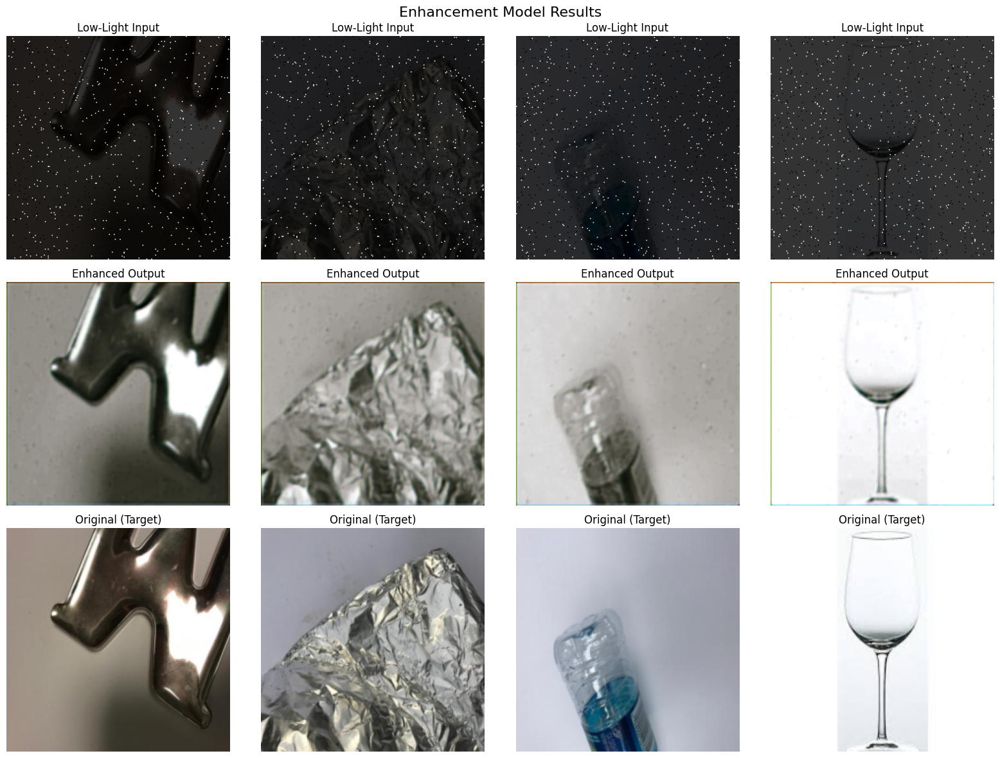

In [32]:
enhancer_model.load_state_dict(torch.load("enhancer_best.pth", map_location=device))
enhancer_model.eval()

sample_low, sample_orig = next(iter(val_enh_loader))
sample_low = sample_low.to(device)

with torch.no_grad():
    sample_enhanced = enhancer_model(sample_low)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for i in range(4):
    axes[0, i].imshow(sample_low[i].cpu().permute(1, 2, 0).numpy())
    axes[0, i].set_title('Low-Light Input')
    axes[0, i].axis('off')

    axes[1, i].imshow(sample_enhanced[i].cpu().permute(1, 2, 0).numpy().clip(0, 1))
    axes[1, i].set_title('Enhanced Output')
    axes[1, i].axis('off')

    axes[2, i].imshow(sample_orig[i].permute(1, 2, 0).numpy())
    axes[2, i].set_title('Original (Target)')
    axes[2, i].axis('off')

plt.suptitle('Enhancement Model Results', fontsize=16)
plt.tight_layout()
plt.show()

Calculating losses: 100%|██████████| 15/15 [00:10<00:00,  1.46it/s]


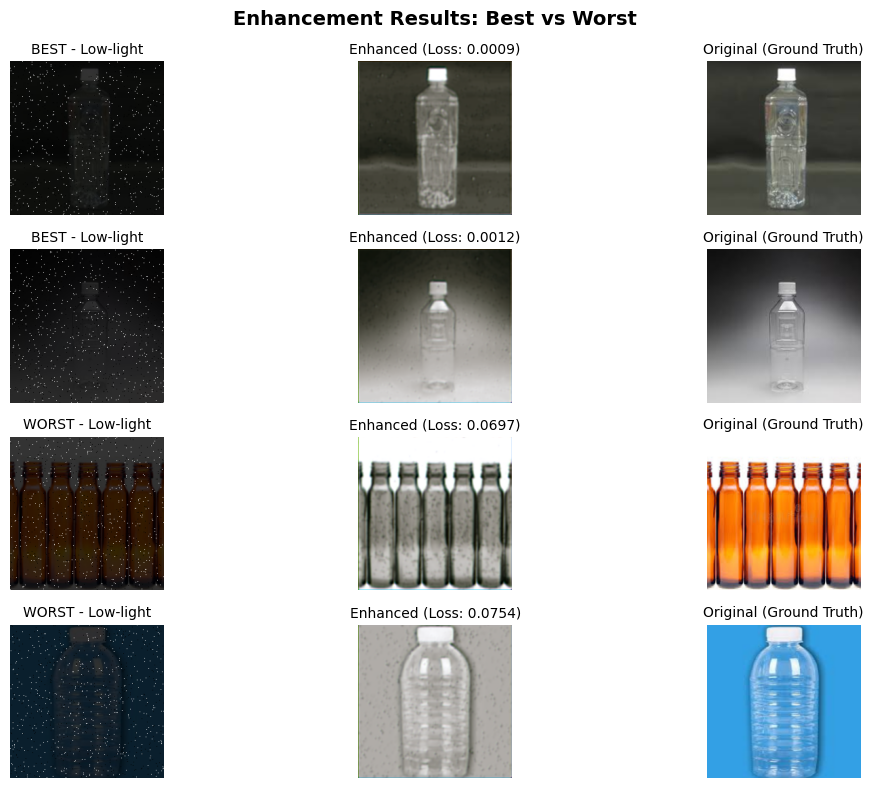

In [33]:
def visualize_best_worst_enhancement(enhancer, loader, num_each=2):
    enhancer.eval()

    results = []

    with torch.no_grad():
        for low_light, original in tqdm(loader, desc="Calculating losses"):
            low_light = low_light.to(device)
            original = original.to(device)

            enhanced = enhancer(low_light)

            for i in range(low_light.size(0)):
                loss = F.mse_loss(enhanced[i], original[i]).item()
                results.append({
                    'loss': loss,
                    'low_light': low_light[i].cpu(),
                    'enhanced': enhanced[i].cpu(),
                    'original': original[i].cpu()
                })

    results.sort(key=lambda x: x['loss'])

    best = results[:num_each]
    worst = results[-num_each:]

    fig, axes = plt.subplots(2 * num_each, 3, figsize=(12, 4 * num_each))

    all_samples = best + worst
    labels = ['BEST'] * num_each + ['WORST'] * num_each

    for idx, (sample, label) in enumerate(zip(all_samples, labels)):
        axes[idx, 0].imshow(sample['low_light'].permute(1, 2, 0).numpy().clip(0, 1))
        axes[idx, 0].set_title(f"{label} - Low-light", fontsize=10)
        axes[idx, 0].axis('off')

        axes[idx, 1].imshow(sample['enhanced'].permute(1, 2, 0).numpy().clip(0, 1))
        axes[idx, 1].set_title(f"Enhanced (Loss: {sample['loss']:.4f})", fontsize=10)
        axes[idx, 1].axis('off')

        axes[idx, 2].imshow(sample['original'].permute(1, 2, 0).numpy().clip(0, 1))
        axes[idx, 2].set_title("Original (Ground Truth)", fontsize=10)
        axes[idx, 2].axis('off')

    plt.suptitle("Enhancement Results: Best vs Worst", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

enhancer_model.load_state_dict(torch.load("enhancer_best.pth", map_location=device))
visualize_best_worst_enhancement(enhancer_model, val_enh_loader, num_each=2)

In [34]:
enhancer_model.load_state_dict(torch.load("enhancer_best.pth", map_location=device))
classifier_model.load_state_dict(torch.load("classifier_best.pth", map_location=device))

RuntimeError: Error(s) in loading state_dict for ClassificationCNN:
	Missing key(s) in state_dict: "conv1.weight", "conv1.bias", "bn1.weight", "bn1.bias", "bn1.running_mean", "bn1.running_var", "conv2.weight", "conv2.bias", "bn2.weight", "bn2.bias", "bn2.running_mean", "bn2.running_var", "conv3.weight", "conv3.bias", "fc1.weight", "fc1.bias", "fc2.weight", "fc2.bias", "fc3.weight", "fc3.bias", "classifier.weight", "classifier.bias". 
	Unexpected key(s) in state_dict: "model.conv1.weight", "model.bn1.weight", "model.bn1.bias", "model.bn1.running_mean", "model.bn1.running_var", "model.bn1.num_batches_tracked", "model.layer1.0.conv1.weight", "model.layer1.0.bn1.weight", "model.layer1.0.bn1.bias", "model.layer1.0.bn1.running_mean", "model.layer1.0.bn1.running_var", "model.layer1.0.bn1.num_batches_tracked", "model.layer1.0.conv2.weight", "model.layer1.0.bn2.weight", "model.layer1.0.bn2.bias", "model.layer1.0.bn2.running_mean", "model.layer1.0.bn2.running_var", "model.layer1.0.bn2.num_batche

In [31]:
print("="*60)
print("STAGE 2: Training Classification Model (with Enhancement Pipeline)")
print("="*60)
print(f"Epochs: {CLASSIFIER_EPOCHS}")
print(f"Training samples: {len(train_clf_ds)} (includes augmented)")
print(f"Enhancement model: FROZEN")
print("-"*60)

best_clf_loss = float('inf')
classifier_history_base = []

for epoch in range(1, CLASSIFIER_EPOCHS + 1):
    train_loss, train_acc = train_classifier_epoch(
        enhancer_model, classifier_model, train_clf_loader,
        classifier_optimizer, classifier_criterion, epoch
    )

    val_loss, val_acc = validate_classifier(
        enhancer_model, classifier_model, val_clf_loader,
        classifier_criterion
    )

    classifier_history_base.append((train_loss, val_loss, train_acc, val_acc))

    if val_loss < best_clf_loss:
        best_clf_loss = val_loss
        torch.save(classifier_model.state_dict(), "classifier_best.pth")
        save_marker = " ✓ Saved"
    else:
        save_marker = ""

    print(f"Epoch {epoch:3d}/{CLASSIFIER_EPOCHS} | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%{save_marker}")

print("-"*60)
print(f"Best Validation Loss: {best_clf_loss:.4f}")
print("Classification Model Training Complete!")

STAGE 2: Training Classification Model (with Enhancement Pipeline)
Epochs: 15
Training samples: 7512 (includes augmented)
Enhancement model: FROZEN
------------------------------------------------------------


Classifier Epoch 1:   2%|▏         | 2/118 [00:02<02:19,  1.20s/it, acc=28.9%, loss=5.5446]


KeyboardInterrupt: 

In [35]:
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
classifier_model = RecyclingVGG(num_classes=num_classes).to(device)
classifier_optimizer = optim.Adam(classifier_model.parameters(), lr=CLASSIFIER_LR)
classifier_criterion = FocalLoss(gamma = 2.0).to(device)
print(f"\n[Model 3] Classification CNN_VGG")
print(f"  - Purpose: Classify garbage into {num_classes} categories")
print(f"  - Loss: CrossEntropy")
print(f"  - Learning Rate: {CLASSIFIER_LR}")


[Model 3] Classification CNN_VGG
  - Purpose: Classify garbage into 4 categories
  - Loss: CrossEntropy
  - Learning Rate: 0.0003


In [ ]:
print("="*60)
print("STAGE 3: Training VGG Classification Model (with Enhancement Pipeline)")
print("="*60)
print(f"Epochs: {CLASSIFIER_EPOCHS}")
print(f"Training samples: {len(train_clf_ds)} (includes augmented)")
print(f"Enhancement model: FROZEN")
print("-"*60)

best_clf_loss = float('inf')
classifier_history_vgg = []

for epoch in range(1, CLASSIFIER_EPOCHS + 1):
    train_loss, train_acc = train_classifier_epoch(
        enhancer_model, classifier_model, train_clf_loader,
        classifier_optimizer, classifier_criterion, epoch
    )

    val_loss, val_acc = validate_classifier(
        enhancer_model, classifier_model, val_clf_loader,
        classifier_criterion
    )

    classifier_history_vgg.append((train_loss, val_loss, train_acc, val_acc))

    if val_loss < best_clf_loss:
        best_clf_loss = val_loss
        torch.save(classifier_model.state_dict(), "classifier_best_VGG.pth")
        save_marker = " ✓ Saved"
    else:
        save_marker = ""

    print(f"Epoch {epoch:3d}/{CLASSIFIER_EPOCHS} | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%{save_marker}")

print("-"*60)
print(f"Best Validation Loss: {best_clf_loss:.4f}")
print("Classification Model Training Complete!")

STAGE 3: Training VGG Classification Model (with Enhancement Pipeline)
Epochs: 15
Training samples: 7512 (includes augmented)
Enhancement model: FROZEN
------------------------------------------------------------


Classifier Epoch 1: 100%|██████████| 118/118 [01:19<00:00,  1.48it/s, acc=72.7%, loss=0.2181]


Epoch   1/15 | Train Loss: 0.3193 | Train Acc: 72.72% | Val Loss: 0.1888 | Val Acc: 82.91% ✓ Saved


Classifier Epoch 2: 100%|██████████| 118/118 [01:20<00:00,  1.46it/s, acc=82.5%, loss=0.1472]


Epoch   2/15 | Train Loss: 0.1885 | Train Acc: 82.53% | Val Loss: 0.2151 | Val Acc: 81.31%


Classifier Epoch 3: 100%|██████████| 118/118 [01:21<00:00,  1.44it/s, acc=85.5%, loss=0.1719]


... (21 outputs left out)

Classifier Epoch 14: 100%|██████████| 118/118 [01:43<00:00,  1.14it/s, acc=93.2%, loss=0.0445]


Epoch  14/15 | Train Loss: 0.0742 | Train Acc: 93.21% | Val Loss: 0.1170 | Val Acc: 90.58% ✓ Saved


Classifier Epoch 15: 100%|██████████| 118/118 [01:42<00:00,  1.15it/s, acc=93.2%, loss=0.0159]


Epoch  15/15 | Train Loss: 0.0725 | Train Acc: 93.21% | Val Loss: 0.1056 | Val Acc: 91.48% ✓ Saved
------------------------------------------------------------
Best Validation Loss: 0.1056
Classification Model Training Complete!


In [40]:
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
classifier_model = RecyclingResNet50(num_classes=num_classes).to(device)
classifier_optimizer = optim.Adam(classifier_model.parameters(), lr=CLASSIFIER_LR)
classifier_criterion = FocalLoss(gamma = 2.0).to(device)
print(f"\n[Model 3] Classification CNN_ResNet50")
print(f"  - Purpose: Classify garbage into {num_classes} categories")
print(f"  - Loss: CrossEntropy")
print(f"  - Learning Rate: {CLASSIFIER_LR}")


[Model 3] Classification CNN_ResNet50
  - Purpose: Classify garbage into 4 categories
  - Loss: CrossEntropy
  - Learning Rate: 0.0003


In [ ]:
print("="*60)
print("STAGE 3: Training ResNet50 Classification Model (with Enhancement Pipeline)")
print("="*60)
print(f"Epochs: {CLASSIFIER_EPOCHS}")
print(f"Training samples: {len(train_clf_ds)} (includes augmented)")
print(f"Enhancement model: FROZEN")
print("-"*60)

best_clf_loss = float('inf')
classifier_history_res = []

for epoch in range(1, CLASSIFIER_EPOCHS + 1):
    train_loss, train_acc = train_classifier_epoch(
        enhancer_model, classifier_model, train_clf_loader,
        classifier_optimizer, classifier_criterion, epoch
    )

    val_loss, val_acc = validate_classifier(
        enhancer_model, classifier_model, val_clf_loader,
        classifier_criterion
    )

    classifier_history_res.append((train_loss, val_loss, train_acc, val_acc))

    if val_loss < best_clf_loss:
        best_clf_loss = val_loss
        torch.save(classifier_model.state_dict(), "classifier_best_ResNet50.pth")
        save_marker = " ✓ Saved"
    else:
        save_marker = ""

    print(f"Epoch {epoch:3d}/{CLASSIFIER_EPOCHS} | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%{save_marker}")

print("-"*60)
print(f"Best Validation Loss: {best_clf_loss:.4f}")
print("Classification Model Training Complete!")

STAGE 3: Training ResNet50 Classification Model (with Enhancement Pipeline)
Epochs: 15
Training samples: 7512 (includes augmented)
Enhancement model: FROZEN
------------------------------------------------------------


Classifier Epoch 1: 100%|██████████| 118/118 [01:06<00:00,  1.78it/s, acc=59.9%, loss=0.3900]


Epoch   1/15 | Train Loss: 0.5185 | Train Acc: 59.94% | Val Loss: 0.3912 | Val Acc: 70.55% ✓ Saved


Classifier Epoch 2: 100%|██████████| 118/118 [01:05<00:00,  1.79it/s, acc=72.6%, loss=0.3751]


Epoch   2/15 | Train Loss: 0.3539 | Train Acc: 72.64% | Val Loss: 0.3109 | Val Acc: 75.99% ✓ Saved


Classifier Epoch 3: 100%|██████████| 118/118 [01:29<00:00,  1.32it/s, acc=76.4%, loss=0.2133]


... (21 outputs left out)

Classifier Epoch 14: 100%|██████████| 118/118 [01:36<00:00,  1.23it/s, acc=85.0%, loss=0.1279]


Epoch  14/15 | Train Loss: 0.1767 | Train Acc: 85.02% | Val Loss: 0.1785 | Val Acc: 85.36%


Classifier Epoch 15: 100%|██████████| 118/118 [01:35<00:00,  1.23it/s, acc=85.9%, loss=0.1581]


Epoch  15/15 | Train Loss: 0.1706 | Train Acc: 85.94% | Val Loss: 0.1746 | Val Acc: 85.57% ✓ Saved
------------------------------------------------------------
Best Validation Loss: 0.1746
Classification Model Training Complete!


In [36]:
def evaluate_pipeline(enhancer, classifier, loader, class_names):
    enhancer.eval()
    classifier.eval()

    y_true = []
    y_pred = []

    print("Running full pipeline evaluation...")
    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Evaluating"):
            images = images.to(device)
            labels = labels.to(device)

            enhanced = enhancer(images)
            normalized = (enhanced - NORM_MEAN) / NORM_STD
            outputs = classifier(normalized)

            _, predicted = torch.max(outputs, 1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='weighted')

    print("\n" + "="*40)
    print("="*40)
    print(f"Global Accuracy: {acc:.2%}")
    print(f"Global F1 Score: {f1:.4f}")
    print("-" * 40)

    print("Classification Report:\n")
    report_dict = classification_report(y_true, y_pred, target_names=classes, output_dict=True)
    print(classification_report(y_true, y_pred, target_names=classes))

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))

    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes, ax=axes[0])
    axes[0].set_title('Confusion Matrix')
    axes[0].set_xlabel('Predicted Label')
    axes[0].set_ylabel('True Label')

    class_names = []
    class_scores = []
    for cls in classes:
        class_names.append(cls)
        class_scores.append(report_dict[cls]['f1-score'])

    sns.barplot(x=class_names, y=class_scores, palette='viridis', ax=axes[1])
    axes[1].set_title('F1 Score per Class')
    axes[1].set_ylim(0, 1.0)
    axes[1].set_ylabel('F1 Score')

    for i, v in enumerate(class_scores):
        axes[1].text(i, v + 0.01, f"{v:.2f}", ha='center', fontweight='bold')

    plt.tight_layout()
    plt.show()

    return {
        "accuracy": acc,
        "f1": f1,
        "y_true": y_true,
        "y_pred": y_pred
    }
def plot_history(history):
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history['train_loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()

In [37]:
enhancer_model.load_state_dict(torch.load("enhancer_best.pth", map_location=device))
classifier_model_VGG = RecyclingVGG(num_classes=num_classes).to(device)
classifier_model_VGG.load_state_dict(torch.load("classifier_best_VGG.pth", map_location=device))
classifier_model_RES = RecyclingResNet50(num_classes=num_classes).to(device)
classifier_model_RES.load_state_dict(torch.load("classifier_best_ResNet50.pth", map_location=device))
class_names = datasets.ImageFolder(DATA_DIR).classes
classifier_model_base = ClassificationCNN(num_classes=num_classes).to(device)
classifier_model_base.load_state_dict(torch.load("classifier_best.pth", map_location=device))


RuntimeError: Error(s) in loading state_dict for ClassificationCNN:
	Missing key(s) in state_dict: "conv1.weight", "conv1.bias", "bn1.weight", "bn1.bias", "bn1.running_mean", "bn1.running_var", "conv2.weight", "conv2.bias", "bn2.weight", "bn2.bias", "bn2.running_mean", "bn2.running_var", "conv3.weight", "conv3.bias", "fc1.weight", "fc1.bias", "fc2.weight", "fc2.bias", "fc3.weight", "fc3.bias", "classifier.weight", "classifier.bias". 
	Unexpected key(s) in state_dict: "model.conv1.weight", "model.bn1.weight", "model.bn1.bias", "model.bn1.running_mean", "model.bn1.running_var", "model.bn1.num_batches_tracked", "model.layer1.0.conv1.weight", "model.layer1.0.bn1.weight", "model.layer1.0.bn1.bias", "model.layer1.0.bn1.running_mean", "model.layer1.0.bn1.running_var", "model.layer1.0.bn1.num_batches_tracked", "model.layer1.0.conv2.weight", "model.layer1.0.bn2.weight", "model.layer1.0.bn2.bias", "model.layer1.0.bn2.running_mean", "model.layer1.0.bn2.running_var", "model.layer1.0.bn2.num_batche

Running full pipeline evaluation...


Evaluating: 100%|██████████| 30/30 [00:44<00:00,  1.49s/it]



       PIPELINE EVALUATION REPORT
Accuracy: 0.8312 (83.12%)
F1 Score: 0.8279

Classification Report:

              precision    recall  f1-score   support

       glass       0.85      0.88      0.86       804
       metal       0.79      0.66      0.72       308
       paper       0.83      0.95      0.89       420
     plastic       0.83      0.73      0.77       346

    accuracy                           0.83      1878
   macro avg       0.82      0.80      0.81      1878
weighted avg       0.83      0.83      0.83      1878



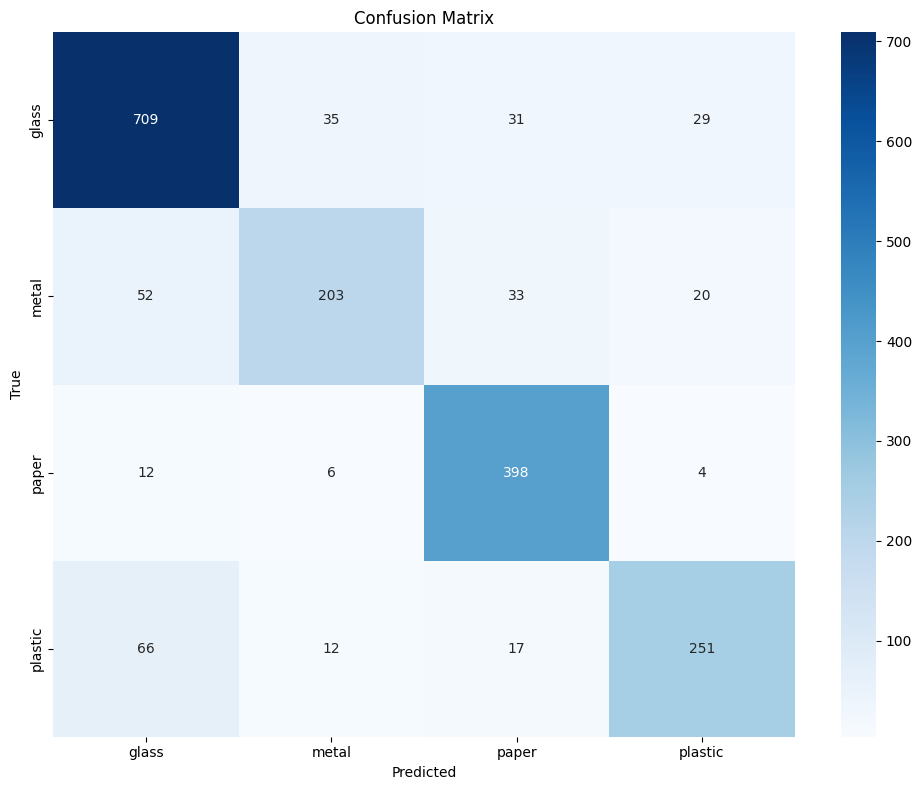

In [ ]:
results = evaluate_pipeline(enhancer_model, classifier_model_base, val_clf_loader, class_names)

Running full pipeline evaluation...


Evaluating: 100%|██████████| 30/30 [01:01<00:00,  2.05s/it]
C:\Users\deniz\AppData\Local\Temp\ipykernel_20680\1040369280.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_names, y=class_scores, palette='viridis', ax=axes[1])



Global Accuracy: 90.95%
Global F1 Score: 0.9089
----------------------------------------
Classification Report:

              precision    recall  f1-score   support

       glass       0.92      0.92      0.92       804
       metal       0.91      0.88      0.89       308
       paper       0.91      0.97      0.94       420
     plastic       0.89      0.84      0.86       346

    accuracy                           0.91      1878
   macro avg       0.91      0.90      0.90      1878
weighted avg       0.91      0.91      0.91      1878



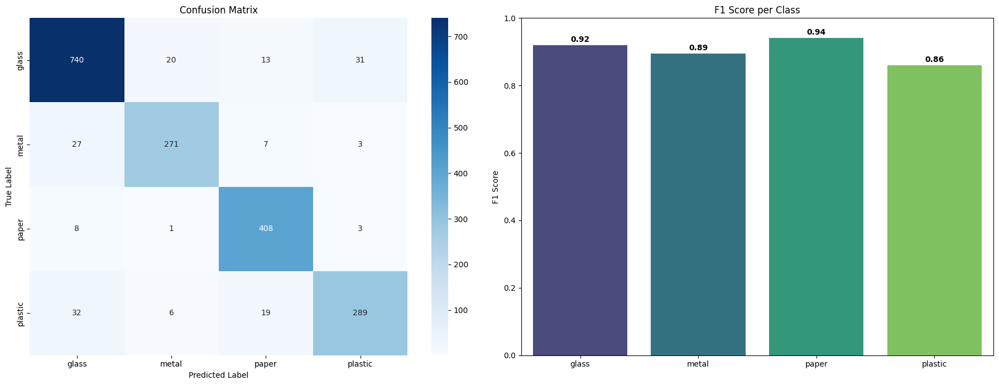

In [43]:
results = evaluate_pipeline(enhancer_model, classifier_model_VGG, val_clf_loader, class_names)

Running full pipeline evaluation...


Evaluating: 100%|██████████| 30/30 [00:37<00:00,  1.25s/it]


Global Accuracy: 85.04%
Global F1 Score: 0.8512
----------------------------------------
Classification Report:

              precision    recall  f1-score   support

       glass       0.88      0.87      0.88       804
       metal       0.82      0.79      0.81       308
       paper       0.93      0.90      0.91       420
     plastic       0.72      0.78      0.75       346

    accuracy                           0.85      1878
   macro avg       0.84      0.84      0.84      1878
weighted avg       0.85      0.85      0.85      1878




C:\Users\deniz\AppData\Local\Temp\ipykernel_14236\2001563139.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_names, y=class_scores, palette='viridis', ax=axes[1])


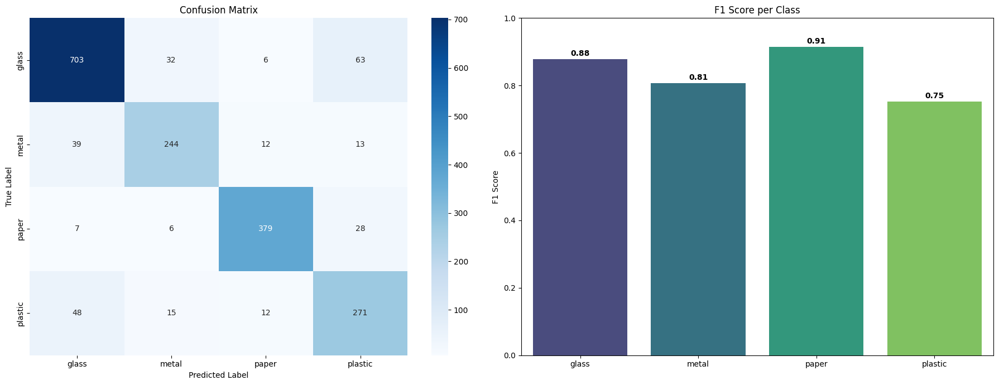

In [45]:
results = evaluate_pipeline(enhancer_model, classifier_model_RES, val_clf_loader, class_names)

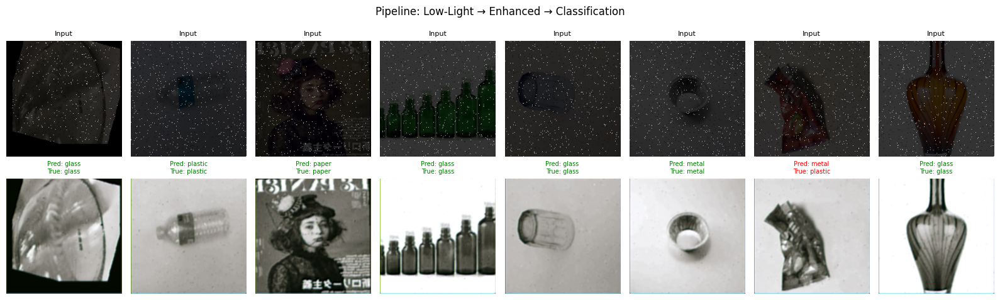

In [44]:
def visualize_pipeline_predictions(enhancer, classifier, loader, class_names, num_samples=8):
    enhancer.eval()
    classifier.eval()

    images, labels = next(iter(loader))
    images = images[:num_samples].to(device)
    labels = labels[:num_samples]

    with torch.no_grad():
        enhanced = enhancer(images)
        normalized = (enhanced - NORM_MEAN) / NORM_STD
        outputs = classifier(normalized)
        _, predicted = torch.max(outputs, 1)

    fig, axes = plt.subplots(2, num_samples, figsize=(2*num_samples, 5))

    for i in range(num_samples):
        axes[0, i].imshow(images[i].cpu().permute(1, 2, 0).numpy())
        axes[0, i].set_title('Input', fontsize=8)
        axes[0, i].axis('off')

        axes[1, i].imshow(enhanced[i].cpu().permute(1, 2, 0).numpy().clip(0, 1))
        pred_label = class_names[predicted[i]]
        true_label = class_names[labels[i]]
        color = 'green' if pred_label == true_label else 'red'
        axes[1, i].set_title(f'Pred: {pred_label}\nTrue: {true_label}', fontsize=7, color=color)
        axes[1, i].axis('off')

    plt.suptitle('Pipeline: Low-Light → Enhanced → Classification', fontsize=12)
    plt.tight_layout()
    plt.show()

visualize_pipeline_predictions(enhancer_model, classifier_model_VGG, val_clf_loader, class_names)

In [45]:
def predict_image(image_path, enhancer, classifier, class_names):
    enhancer.eval()
    classifier.eval()

    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (256, 256))

    start = (256 - IMAGE_SIZE) // 2
    img = img[start:start+IMAGE_SIZE, start:start+IMAGE_SIZE]

    img_low = apply_low_light(img, BRIGHTNESS_FACTOR, NOISE_RATIO)

    img_tensor = torch.from_numpy(img_low).permute(2, 0, 1).float() / 255.0
    img_tensor = img_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        enhanced = enhancer(img_tensor)
        normalized = (enhanced - NORM_MEAN) / NORM_STD
        output = classifier(normalized)
        _, predicted = torch.max(output, 1)

    pred_class = class_names[predicted.item()]

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(img)
    axes[0].set_title('Original')
    axes[0].axis('off')

    axes[1].imshow(img_low)
    axes[1].set_title('Low-Light')
    axes[1].axis('off')

    axes[2].imshow(enhanced[0].cpu().permute(1, 2, 0).numpy().clip(0, 1))
    axes[2].set_title(f'Enhanced → Predicted: {pred_class}')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

    return pred_class

print("Usage: predict_image('path/to/image.jpg', enhancer_model, classifier_model, class_names)")

Usage: predict_image('path/to/image.jpg', enhancer_model, classifier_model, class_names)



Predicting for image: images2.jpeg


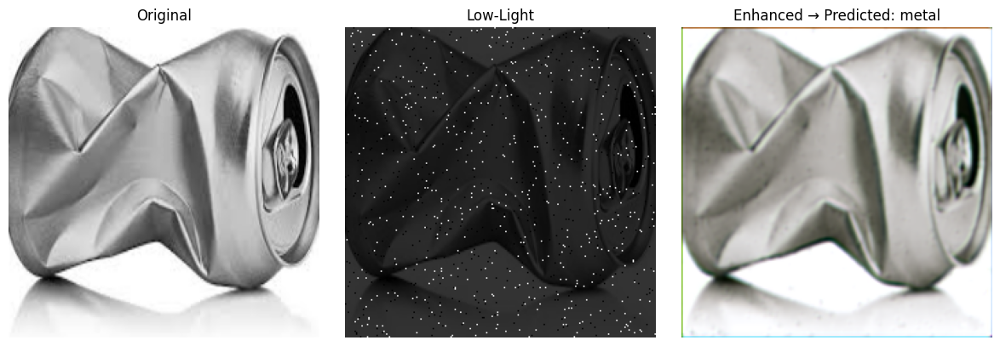

Predicted Class: metal

Predicting for image: image_1.png


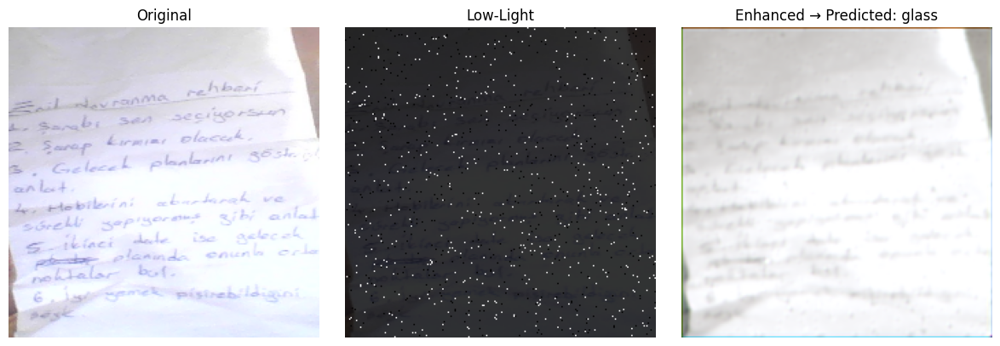

Predicted Class: glass

Predicting for image: IMG_20260111_174059.jpg


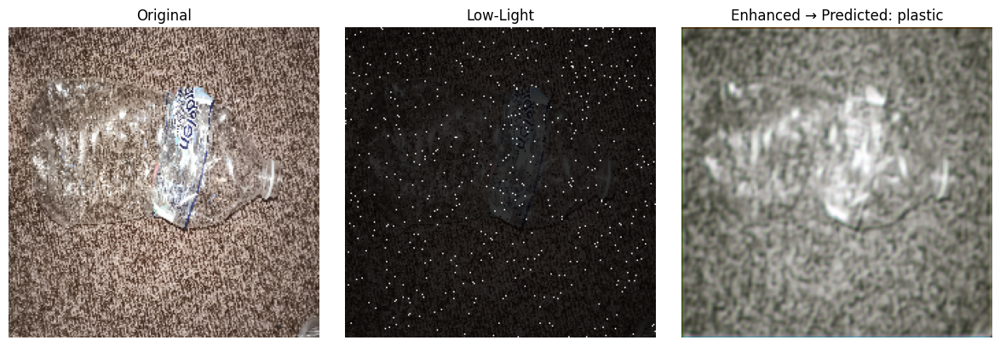

Predicted Class: plastic

Predicting for image: IMG_20260111_174106.jpg


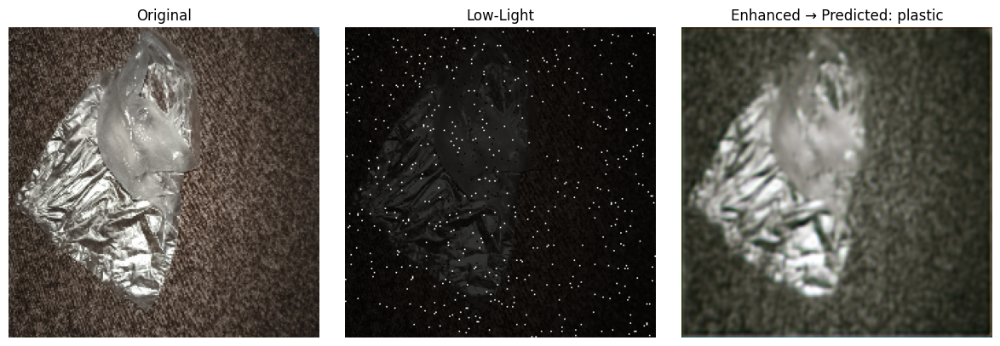

Predicted Class: plastic

Predicting for image: IMG_20260111_174120.jpg


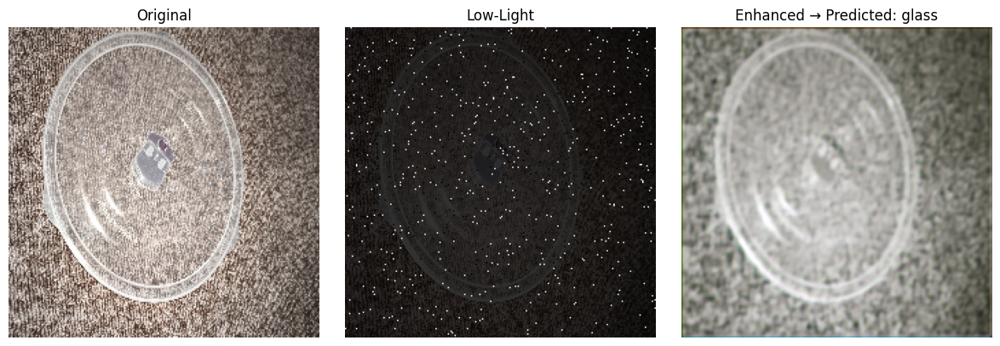

Predicted Class: glass

Predicting for image: IMG_20260111_174212.jpg


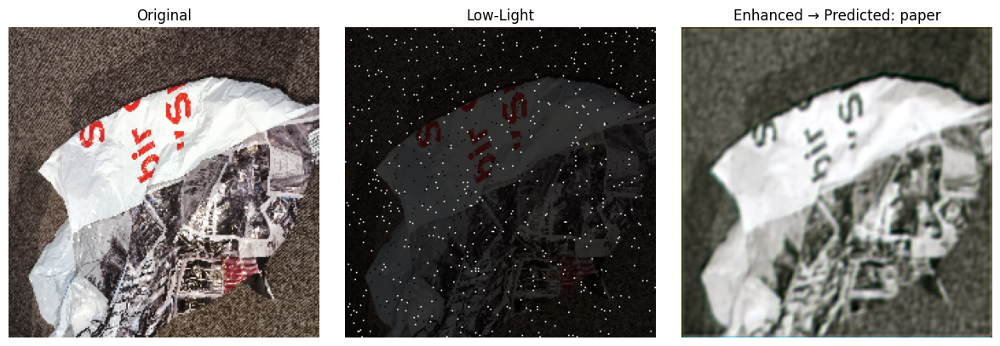

Predicted Class: paper

Predicting for image: IMG_20260111_174414.jpg


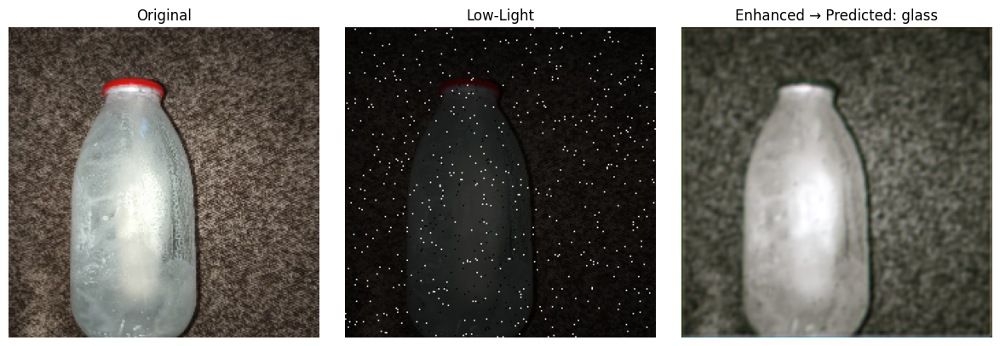

Predicted Class: glass

Predicting for image: IMG_20260111_174436.jpg


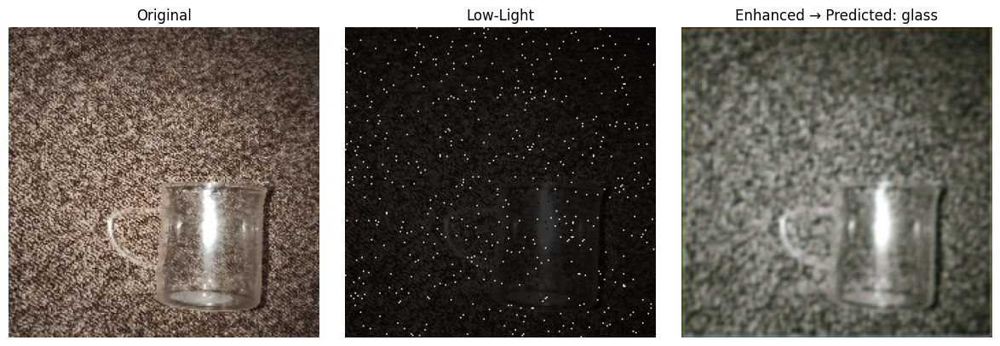

Predicted Class: glass

Predicting for image: IMG_20260111_174709.jpg


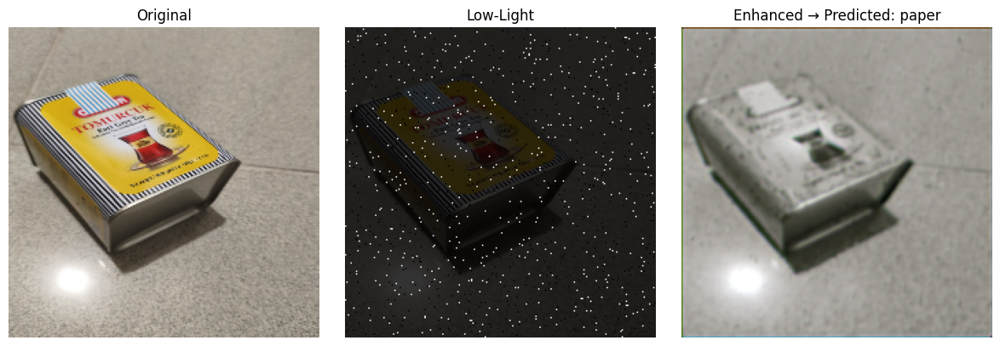

Predicted Class: paper


In [46]:
test_image_path = "test_images"
for img_file in os.listdir(test_image_path):
    if img_file.lower().endswith(('.png', '.jpg', '.jpeg')):
        print(f"\nPredicting for image: {img_file}")
        image_path = os.path.join(test_image_path, img_file)
        predicted_class = predict_image(image_path, enhancer_model, classifier_model_VGG, class_names)
        print(f"Predicted Class: {predicted_class}")